# 05c — Fine-tuning Donut: learn the task, then select on validation

**Phase 4 · Training workshop · Real retained GPU experiment**

Notebook B established the data grammar and a feasible resource policy. This
workshop explains and audits the actual tiny overfit diagnostic and the bounded
main run. You will inspect losses, free-running answers, checkpoint selection,
negative results, and exact provenance rather than assuming training succeeded
because loss decreased.

The [training guide](../docs/learning/donut-training.md) develops teacher forcing,
frozen features, Adafactor, accumulation, schedules, and selection. The
[experiment report](../docs/experiments/donut-finetuning.md) owns named results.

## Execution modes and setup

The expensive GPU experiment **has actually run** through
`experiments/train_donut.py`; its sources, configurations, loss history,
epoch-level generations, and selected weights were retained. By default this
notebook replays those real artifacts, independently scores them, and plots the
results. It does not silently start another multi-minute training run every time
you choose Run All.

To reproduce the training from the pinned parent in a new run directory:

```bash
.venv/bin/python -m experiments.train_donut --config configs/donut_finetuning_v2.json
```

Then execute the review notebook with the repository `.venv`:

```bash
.venv/bin/python -m experiments.execute_phase4_notebook 05c_donut_finetuning
```

The existing frozen manifest identifies the retained experiment reviewed here;
a reproduction does not silently replace it. Keep test sealed. Use a scratch
copy for exercises and make predictions before inspecting the tables.

In [1]:
from pathlib import Path
import hashlib, inspect, json
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display

here=Path.cwd().resolve()
ROOT=next(p for p in [here,*here.parents] if (p/'PROJECT.md').is_file())
from experiments.donut_workshop import read_json, write_json, new_run, sha
from experiments.train_donut import make_optimizer, check_gradients
from kyc_router.evaluation import score_document, summarize_scores
from kyc_router.normalization import normalize_document_values
manifest=read_json(ROOT/'configs/donut_pipeline_v1.json')
TRAINING=ROOT/manifest['training_evidence']
REVIEW=new_run('phase4_training_review')
completion=read_json(TRAINING/'completion.json')
config=read_json(TRAINING/'training_policy.json')
history=pd.DataFrame(read_json(TRAINING/'history.json'))
tiny=read_json(TRAINING/'tiny_overfit.json')
assert completion['status']=='completed' and completion['test_evaluated'] is False
print('Retained training run:',TRAINING.relative_to(ROOT))
print('Review evidence:',REVIEW.relative_to(ROOT))

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Retained training run: outputs/phase4_finetuning/20261015T122657718426Z
Review evidence: outputs/phase4_training_review/20261015T123836282599Z


## 1. Establish what was trained and what remained fixed

The pretrained image encoder remains fixed. All decoder parameters—including
new schema-token embeddings—are trainable. Precomputed whole-image features save
repeated encoder work during fitting; they contain no answer text. During cached
validation generation the frozen encoder is temporarily co-located with the
decoder because the parent generation helper uses its device and encoder-decoder
cache semantics. The deployed path always encodes its new input image.

Read the declared budget and selection rule **before** looking for a good epoch.
The actual run initializes a tiny diagnostic separately, resets the parent and
seed, then makes main updates only from 140 training views. The 30 validation
views choose checkpoints; they do not produce gradients.

**Predict:** does freezing the encoder make this full-model fine-tuning? Which
part of the task could remain limited by the fixed visual features?

In [2]:
display(pd.Series({
    'adaptation':config['adaptation'],
    'optimizer':config['training']['optimizer'],
    'precision':config['precision'],
    'microbatch':config['training']['microbatch_size'],
    'accumulation':config['training']['gradient_accumulation'],
    'max_epochs':config['training']['max_epochs'],
    'early_stopping_min_epochs':config['training']['early_stopping_min_epochs'],
    'patience':config['training']['early_stopping_patience'],
    'selection':config['selection'],
    'budget':config['budget'],
},name='declared experiment').to_frame())
assert config['tiny_overfit']['reset_before_main_training']
assert sha(ROOT/'configs/donut_finetuning_v2.json')==manifest['training_configuration_sha256']
print('Frozen encoder hash verified after main training:',completion['frozen_encoder_verified'])

,declared experiment
adaptation,frozen pretrained encoder; all decoder paramet...
optimizer,Adafactor
precision,float32
microbatch,1
accumulation,4
max_epochs,24
early_stopping_min_epochs,8
patience,6
selection,{'primary': 'mean of template/photo validation...
budget,one restarted tiny diagnostic after resource-o...


Frozen encoder hash verified after main training: True


## 2. Inspect the update mechanics

Adafactor uses factored second-moment estimates, with no first-moment state.
We choose explicit learning rates, so relative-step and parameter scaling are
disabled. Its RMS update clipping is distinct from the global gradient clipping
used in earlier AdamW probes. The implementation records finite gradient norms
without applying an additional global clip to Adafactor.

Main training uses one variable-length example at a time. Four losses divided
by four accumulate before an optimizer step, giving effective batch size four.
There are exactly 140 training observations, so each epoch has 35 complete update
groups and no partial-group weighting ambiguity. Warm-up gradually reaches the
declared learning rate; a linear schedule then decays toward zero at the maximum
budget. Early stopping can end training before that schedule reaches its end.

In [3]:
print(inspect.getsource(make_optimizer))
print(inspect.getsource(check_gradients))
tc=config['training']
updates_per_epoch=140//tc['gradient_accumulation']
assert 140 % tc['gradient_accumulation']==0
print('Optimizer updates per epoch:',updates_per_epoch)
print('Warm-up optimizer updates:',tc['warmup_optimizer_steps'])
print('Maximum optimizer updates:',updates_per_epoch*tc['max_epochs'])
display(history[['epoch','mean_training_loss','lr_next']])

def make_optimizer(parameters, config, lr):
    tc = config["training"]
    if tc["optimizer"] == "Adafactor":
        options = dict(tc["adafactor"])
        options["eps"] = tuple(options["eps"])
        return Adafactor(parameters, lr=lr, weight_decay=tc["weight_decay"], **options)
    return torch.optim.AdamW(parameters, lr=lr, weight_decay=tc["weight_decay"],
                            betas=tuple(tc["betas"]), eps=tc["epsilon"],
                            foreach=tc["foreach"], fused=tc["fused"])

def check_gradients(parameters, config):
    if config["training"]["gradient_clip_norm"] is not None:
        norm = torch.nn.utils.clip_grad_norm_(parameters, config["training"]["gradient_clip_norm"])
    else:
        norm = torch.linalg.vector_norm(torch.stack([p.grad.detach().norm() for p in parameters if p.grad is not None]))
    assert torch.isfinite(norm)
    return norm

Optimizer updates per epoch: 35
Warm-up optimizer updates: 35
Maximum optimizer updates: 840


,epoch,mean_training_loss,lr_next
0,1,8.972309,0.000050
1,2,1.096801,0.000048
2,3,0.254554,0.000046
3,4,0.114009,0.000043
4,5,0.065370,0.000041
5,6,0.039962,0.000039
6,7,0.018352,0.000037
7,8,0.019225,0.000035
8,9,0.016599,0.000033
9,10,0.020459,0.000030


## 3. Use tiny memorization as an implementation diagnostic

The tiny set contains both views of the first training identity. Their targets
are identical, so successful memorization does not show that the model has
learned to read unseen identities. Its purpose is narrower: can registered
schema tokens, labels, gradients, and free generation cooperate at all?

The criterion is all 14 fields correct under free generation across two views,
not merely a low teacher-forced loss. The check runs at declared intervals and
stops within its fixed budget. Those weights are discarded before main training.

**Predict:** can a nonzero loss coexist with a perfectly correct greedy answer?
The correct token only needs to win the decision; its probability need not be one.

,step,correct_fields
0,20,14


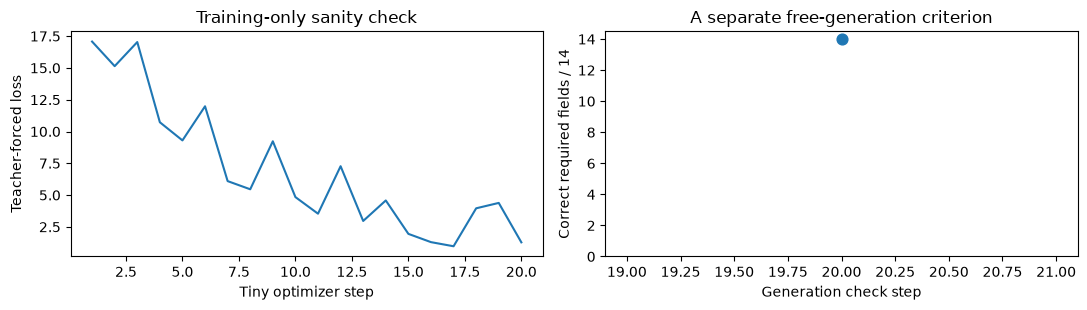

template '<s_alb_id><s_document_number> 391378355</s_document_number><s_surname> ahmeti</s_surname><s_given_names> agim</s_given_names><s_date_of_birth> 1973-10-15</s_date_of_birth><s_expiry_date> 2025-08-07</s_expiry_date><s_nationality> shqiptare/albanian</s_nationality><s_sex> M</s_sex></s>'
photo '<s_alb_id><s_document_number> 391378355</s_document_number><s_surname> ahmeti</s_surname><s_given_names> agim</s_given_names><s_date_of_birth> 1973-10-15</s_date_of_birth><s_expiry_date> 2025-08-07</s_expiry_date><s_nationality> shqiptare/albanian</s_nationality><s_sex> M</s_sex></s>'


In [4]:
tiny_loss=pd.DataFrame(tiny['losses'])
tiny_scores=pd.DataFrame([{k:e[k] for k in ('step','correct_fields')} for e in tiny['evaluations']])
display(tiny_scores)
assert int(tiny_scores.iloc[-1].correct_fields)==14
fig,axes=plt.subplots(1,2,figsize=(11,3.2))
axes[0].plot(tiny_loss.step,tiny_loss.loss)
axes[0].set(xlabel='Tiny optimizer step',ylabel='Teacher-forced loss',title='Training-only sanity check')
axes[1].scatter(tiny_scores.step,tiny_scores.correct_fields,s=60)
axes[1].set(xlabel='Generation check step',ylabel='Correct required fields / 14',ylim=(0,14.5),title='A separate free-generation criterion')
fig.tight_layout();fig.savefig(REVIEW/'tiny_overfit.png',bbox_inches='tight');plt.show()
for record in tiny['evaluations'][-1]['predictions']:
    print(record['source'],repr(record['raw_sequence']))

## 4. Read learning curves without selecting on training loss

Main losses and validation generations answer different questions. Teacher
forcing supplies the correct preceding tokens; free generation uses the model's
own prefix. An early epoch can therefore lose every field to malformed output
even while the average training loss is falling.

Plot all epochs, including regressions. A later lower-loss checkpoint is not
automatically selected. Our primary criterion is the equal-source mean macro
Field EM, then lower pooled CER, then the earlier epoch. Constant nationality
remains one required field; later diagnostics will show it separately.

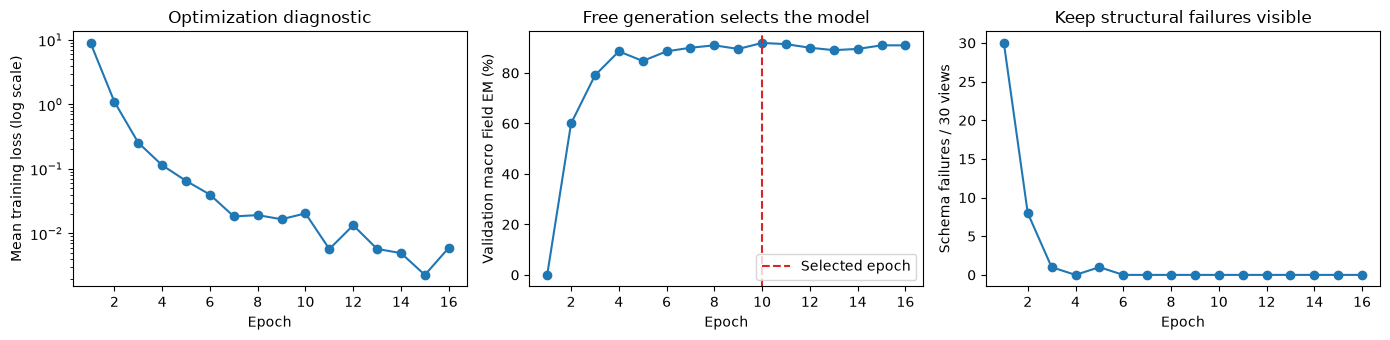

,epoch,mean_training_loss,validation_macro_field_em,pooled_cer,correct_fields,schema_failures,lr_next,seconds,selected_at_this_epoch
0,1,8.972309,0.000000,1.000000,0,30,0.000050,33.196228,True
1,2,1.096801,0.600000,0.286498,126,8,0.000048,15.479877,True
2,3,0.254554,0.790476,0.098793,166,1,0.000046,15.811978,True
3,4,0.114009,0.885714,0.037322,186,0,0.000043,15.753651,True
4,5,0.065370,0.847619,0.056531,178,1,0.000041,15.753584,False
5,6,0.039962,0.885714,0.017563,186,0,0.000039,15.705038,True
6,7,0.018352,0.900000,0.014819,189,0,0.000037,15.761387,True
7,8,0.019225,0.909524,0.013721,191,0,0.000035,15.759478,True
8,9,0.016599,0.895238,0.016465,188,0,0.000033,15.755911,False
9,10,0.020459,0.919048,0.009330,193,0,0.000030,15.724701,True


In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
axes[0].plot(history.epoch,history.mean_training_loss,marker='o')
axes[0].set(yscale='log',xlabel='Epoch',ylabel='Mean training loss (log scale)',title='Optimization diagnostic')
axes[1].plot(history.epoch,history.validation_macro_field_em*100,marker='o')
axes[1].axvline(manifest['selection']['epoch'],color='tab:red',linestyle='--',label='Selected epoch')
axes[1].set(xlabel='Epoch',ylabel='Validation macro Field EM (%)',title='Free generation selects the model')
axes[1].legend()
axes[2].plot(history.epoch,history.schema_failures,marker='o')
axes[2].set(xlabel='Epoch',ylabel='Schema failures / 30 views',title='Keep structural failures visible')
fig.tight_layout();fig.savefig(REVIEW/'training_history.png',bbox_inches='tight');plt.show()
display(history)

### 4.1 Recompute the selection and replay every epoch's scoring

Select the winner from the saved history using the declared sort order. Then
re-score every retained validation generation using original annotation values
and the shared normalizer/scorer. The training CSVs compared raw strings against
normalized target references; raw-string agreement is therefore not the primary
metric. This replay explicitly retains original annotations while checking that
normalization yields the same selected EM/CER and unchanged denominators.

There are only 15 paired validation identities. Sixteen epoch evaluations do not
create a larger independent sample, and repeated selection limits generalization
claims. No test result is involved.

In [6]:
ranked=history.sort_values(['validation_macro_field_em','pooled_cer','epoch'],ascending=[False,True,True])
selected_epoch=int(ranked.iloc[0].epoch)
assert selected_epoch==manifest['selection']['epoch']==completion['selected']['epoch']
replayed=[]
selected_rows=[];selected_docs=[]
for row in history.itertuples():
    records=read_json(TRAINING/f'validation_epoch_{row.epoch:02d}.json')
    all_fields=[]
    for record in records:
        fields,doc=score_document(record['truth_raw'],record['raw_fields'])
        key={k:record[k] for k in ('identity_key','source')}
        all_fields.extend(fields)
        if row.epoch==selected_epoch:
            selected_rows.extend([{**key,**f} for f in fields])
            selected_docs.append({**key,**doc})
    assert len(records)==30 and len(all_fields)==210
    correct=sum(f['normalized_exact_match'] for f in all_fields)
    cer=sum(f['edit_distance'] for f in all_fields)/sum(f['reference_characters'] for f in all_fields)
    assert correct==row.correct_fields and abs(cer-row.pooled_cer)<1e-12
    replayed.append({'epoch':row.epoch,'correct_fields':correct,'denominator':len(all_fields),'corpus_cer':cer})
display(pd.DataFrame(replayed))
print('Selected epoch:',selected_epoch)
print('Replayed field records:',len(replayed)*210)

,epoch,correct_fields,denominator,corpus_cer
0,1,0,210,1.000000
1,2,126,210,0.286498
2,3,166,210,0.098793
3,4,186,210,0.037322
4,5,178,210,0.056531
5,6,186,210,0.017563
6,7,189,210,0.014819
7,8,191,210,0.013721
8,9,188,210,0.016465
9,10,193,210,0.009330


Selected epoch: 10
Replayed field records: 3360


## 5. Inspect the selected checkpoint's remaining mistakes

Keep the original prediction beside its normalized form and the reference. Do
not add a correction map after seeing the errors. An error that differs by one
character still loses Exact Match, even when corpus CER is low. Validation
checks only plausible form; a valid-looking name/number can still be wrong.

The next notebook compares the same observations against adopted OCR, checks
exact reload/source parity, and measures full inference without the training cache.

In [7]:
field_scores=pd.DataFrame(selected_rows);document_scores=pd.DataFrame(selected_docs)
per_field,summary=summarize_scores(field_scores,document_scores)
display(summary)
display(per_field[['source','field','normalized_matches','samples','field_em','cer']])
errors=field_scores.loc[~field_scores.normalized_exact_match]
display(errors[['identity_key','source','field','raw_ground_truth','raw_prediction','normalized_prediction','prediction_is_valid']])
field_scores.to_csv(REVIEW/'selected_field_scores_original_annotations.csv',index=False)
write_json(REVIEW/'review.json',{
    'training_run':str(TRAINING.relative_to(ROOT)),'selected_epoch':selected_epoch,
    'all_epoch_field_records_replayed':len(replayed)*210,'selected_field_errors':len(errors),
    'history_matches_declared_selection':True,'test_evaluated':False,
})
print('Selected checkpoint:',manifest['checkpoint_relative_path'])
print('Checkpoint files and exact hashes are in configs/donut_pipeline_v1.json.')

,source,documents,field_samples,raw_matches,normalized_matches,raw_field_em,macro_field_em,micro_field_em,edit_distance,reference_characters,cer,document_matches,document_em,schema_failures
0,photo,15,105,0,94,0.0,0.895238,0.895238,11,911,0.012075,6,0.400000,0
1,template,15,105,0,99,0.0,0.942857,0.942857,6,911,0.006586,10,0.666667,0


,source,field,normalized_matches,samples,field_em,cer
0,photo,date_of_birth,15,15,1.000000,0.000000
1,photo,document_number,13,15,0.866667,0.014815
2,photo,expiry_date,15,15,1.000000,0.000000
3,photo,given_names,9,15,0.600000,0.060606
4,photo,nationality,15,15,1.000000,0.000000
5,photo,sex,15,15,1.000000,0.000000
6,photo,surname,12,15,0.800000,0.032609
7,template,date_of_birth,15,15,1.000000,0.000000
8,template,document_number,14,15,0.933333,0.007407
9,template,expiry_date,15,15,1.000000,0.000000


,identity_key,source,field,raw_ground_truth,raw_prediction,normalized_prediction,prediction_is_valid
44,alb_id/12,template,given_names,Aleksander,Aleksandr,aleksandr,True
51,alb_id/12,photo,given_names,Aleksander,alekssander,alekssander,True
64,alb_id/14,photo,surname,Bajrami,bajram,bajram,True
93,alb_id/30,photo,given_names,Ardi,ardii,ardii,True
107,alb_id/32,photo,given_names,Ardit,ardita,ardita,True
114,alb_id/36,template,given_names,Arbërie,arberie,arberie,True
121,alb_id/36,photo,given_names,Arbërie,arberie,arberie,True
127,alb_id/50,template,surname,Corbajram,carbajram,carbajram,True
128,alb_id/50,template,given_names,Astrit,astri,astri,True
134,alb_id/50,photo,surname,Corbajram,carbajram,carbajram,True


Selected checkpoint: checkpoints/phase4_finetuning/20261015T122657718426Z/best
Checkpoint files and exact hashes are in configs/donut_pipeline_v1.json.


## 6. Keep failed engineering attempts historical

The resource investigation includes OOMs under full/frozen-encoder AdamW and a
later tiny diagnostic that exceeded the two-step memory headroom. Separate
generation helpers also exposed CPU/CUDA device and encoder-decoder cache issues
before main training. These failed attempts neither updated the selected model
nor saw validation/test outcomes; the main run resets from the parent. The report
records their exact run IDs and fixes rather than hiding them behind the final curve.

The selected run stores its actual source/config snapshots. Reproduction should
use those sources or verify matching hashes; a newer script with the same filename
is not automatically the code that produced an old measurement.

**Provenance lesson:** an early generation smoke used a positional cache index
without binding the feature to the requested image. Its matching outputs were
invalid as cache-parity evidence and are marked as such in the report. Main
training checked every metadata row; the final verification used correctly keyed
records. Bind identity, source, split, pixel hash, and encoder/processor policy;
then compare features as well as outputs. Repeated model output cannot prove
that two inputs were identical.

In [8]:
snapshots=read_json(TRAINING/'source_hashes.json')
snapshot_checks=[]
for name,digest in snapshots.items():
    saved=TRAINING/'sources'/name
    assert saved.is_file() and sha(saved)==digest
    snapshot_checks.append({'source':name,'saved_snapshot_verified':True,'current_file_matches':sha(ROOT/name)==digest})
display(pd.DataFrame(snapshot_checks))
print('Memory at main completion:',completion['memory'])
print('Main elapsed seconds, excluding feature preparation and tiny diagnostic:',completion['training_seconds'])

,source,saved_snapshot_verified,current_file_matches
0,experiments/train_donut.py,True,True
1,experiments/donut_workshop.py,True,True
2,experiments/donut_protocol.py,True,True
3,configs/donut_dataset_v1.json,True,True
4,configs/donut_finetuning_v2.json,True,True
5,splits/alb_id_v1.csv,True,True


Memory at main completion: {'rss_mib': 2765.03125, 'cuda_allocated_mib': 504.3427734375, 'cuda_reserved_mib': 530.0, 'cuda_peak_allocated_mib': 1676.57861328125, 'cuda_peak_reserved_mib': 2024.0}
Main elapsed seconds, excluding feature preparation and tiny diagnostic: 293.9722018930006


## Reflection and guided exercises

1. Why is tiny-set memorization useful even though it cannot show generalization?
   What evidence proves its weights were not reused in main training?
2. Explain which statistics Adafactor approximates, what the explicit schedule
   controls, and why we do not also apply global clipping in this experiment.
3. Why does the selected checkpoint differ from the lowest training-loss epoch?
   Find one validation regression and describe it with raw counts.
4. Why are structural failures kept in all 210 field denominators? What happens
   to CER when an entire generated document is unparseable?
5. Which claims are limited by the frozen encoder, one layout, constant
   nationality, and repeated selection on only 15 validation identities?

**Exercise A:** re-rank the retained candidates using only training loss as an
explicitly labeled diagnostic. Compare its generated-field score with the adopted
selection; do not replace the frozen model or change the primary metric.

**Exercise B:** inspect one valid-looking wrong name or number in the error
table. Explain what a shape validator can check and what it cannot certify.

**Exercise C:** trace one token from a target through the shifted labels, loss,
gradient, optimizer update, and later greedy decision. Mark every place where
ground truth is available and every place where it must be absent.

Continue with [05d — evaluation and extraction](05d_donut_evaluation.ipynb).
See the [experiment report](../docs/experiments/donut-finetuning.md) for the
complete run inventory and limitations. Phase 4 completion requires that next
verification/comparison work; this notebook alone does not close the phase.